In [1]:
import pandas as pd

data = {
    "Operating Table": ["Chinese SDS-5000", "BET Medical MAX 6000"],
    "Purchase Cost": [3000000, 19000000],
    "Minimum Lifespan": [2, 10],
    "Maximum Lifespan": [3, 15],
}

df = pd.DataFrame(data)

df["Annual Cost (Best Case)"] = (
    df["Purchase Cost"] / df["Maximum Lifespan"]
)

df["Annual Cost (Worst Case)"] = (
    df["Purchase Cost"] / df["Minimum Lifespan"]
)

df

,Operating Table,Purchase Cost,Minimum Lifespan,Maximum Lifespan,Annual Cost (Best Case),Annual Cost (Worst Case)
0,Chinese SDS-5000,3000000,2,3,1.000000e+06,1500000.0
1,BET Medical MAX 6000,19000000,10,15,1.266667e+06,1900000.0


In [2]:
# Number of purchases required over five years
df["Best Case Purchases"] = (
    5 / df["Maximum Lifespan"]
).apply(lambda x: int(x) + (x % 1 > 0))

df["Worst Case Purchases"] = (
    5 / df["Minimum Lifespan"]
).apply(lambda x: int(x) + (x % 1 > 0))

# Five-year replacement expenditure
df["Best Case 5-Year Cost"] = (
    df["Purchase Cost"] * df["Best Case Purchases"]
)

df["Worst Case 5-Year Cost"] = (
    df["Purchase Cost"] * df["Worst Case Purchases"]
)

df

,Operating Table,Purchase Cost,Minimum Lifespan,Maximum Lifespan,Annual Cost (Best Case),Annual Cost (Worst Case),Best Case Purchases,Worst Case Purchases,Best Case 5-Year Cost,Worst Case 5-Year Cost
0,Chinese SDS-5000,3000000,2,3,1.000000e+06,1500000.0,2,3,6000000,9000000
1,BET Medical MAX 6000,19000000,10,15,1.266667e+06,1900000.0,1,1,19000000,19000000


In [11]:
maintenance = {
    "Operating Table": ["Chinese SDS-5000", "BET Medical MAX 6000"],
    "Annual Maintenance": [300000, 250000],
    "Annual Repair Cost": [500000, 200000]
}

maintenance_df = pd.DataFrame(maintenance)

maintenance_df["5-Year Maintenance"] = (
    maintenance_df["Annual Maintenance"] * 5
)

maintenance_df["5-Year Repairs"] = (
    maintenance_df["Annual Repair Cost"] * 5
)

maintenance_df["Total 5-Year Maintenance Cost"] = (
    maintenance_df["5-Year Maintenance"] +
    maintenance_df["5-Year Repairs"]
)
maintenance_df

,Operating Table,Annual Maintenance,Annual Repair Cost,5-Year Maintenance,5-Year Repairs,Total 5-Year Maintenance Cost
0,Chinese SDS-5000,300000,500000,1500000,2500000,4000000
1,BET Medical MAX 6000,250000,200000,1250000,1000000,2250000


In [10]:
tco = {
    "Operating Table": [
        "Chinese SDS-5000",
        "BET Medical MAX 6000"
    ],
    "Best Case Purchase Cost": [6000000, 19000000],
    "Worst Case Purchase Cost": [9000000, 19000000],
    "Maintenance Cost": [1500000, 1250000],
    "Repair Cost": [2500000, 1000000]
}

tco_df = pd.DataFrame(tco)

tco_df["Best Case TCO"] = (
    tco_df["Best Case Purchase Cost"]
    + tco_df["Maintenance Cost"]
    + tco_df["Repair Cost"]
)
tco_df["Worst Case TCO"] = (
    tco_df["Worst Case Purchase Cost"]
    + tco_df["Maintenance Cost"]
    + tco_df["Repair Cost"]
)

tco_df

,Operating Table,Best Case Purchase Cost,Worst Case Purchase Cost,Maintenance Cost,Repair Cost,Best Case TCO,Worst Case TCO
0,Chinese SDS-5000,6000000,9000000,1500000,2500000,10000000,13000000
1,BET Medical MAX 6000,19000000,19000000,1250000,1000000,21250000,21250000


In [9]:
import pandas as pd

downtime = {
    "Operating Table": ["Chinese SDS-5000", "BET Medical MAX 6000"],
    "Downtime Days Per Year": [5, 2],
    "Cost Per Downtime Day": [300000, 300000]
}

downtime_df = pd.DataFrame(downtime)

downtime_df["Annual Downtime Cost"] = (
    downtime_df["Downtime Days Per Year"]
    * downtime_df["Cost Per Downtime Day"]
)

downtime_df["Five-Year Downtime Cost"] = (
    downtime_df["Annual Downtime Cost"] * 5
)

downtime_df

,Operating Table,Downtime Days Per Year,Cost Per Downtime Day,Annual Downtime Cost,Five-Year Downtime Cost
0,Chinese SDS-5000,5,300000,1500000,7500000
1,BET Medical MAX 6000,2,300000,600000,3000000


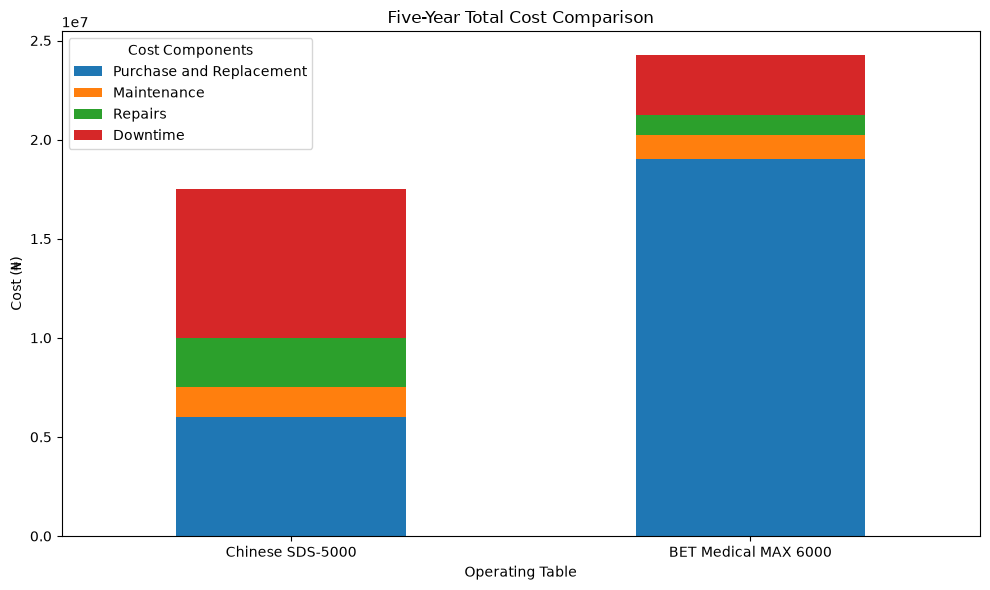

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Combine our five-year cost estimates
comparison = pd.DataFrame({
    "Operating Table": ["Chinese SDS-5000", "BET Medical MAX 6000"],
    "Purchase and Replacement": [6000000, 19000000],
    "Maintenance": [1500000, 1250000],
    "Repairs": [2500000, 1000000],
    "Downtime": [7500000, 3000000]
})

# Plot stacked cost comparison
comparison.set_index("Operating Table").plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Five-Year Total Cost Comparison")
plt.ylabel("Cost (₦)")
plt.xlabel("Operating Table")
plt.xticks(rotation=0)
plt.legend(title="Cost Components")
plt.tight_layout()
plt.show()

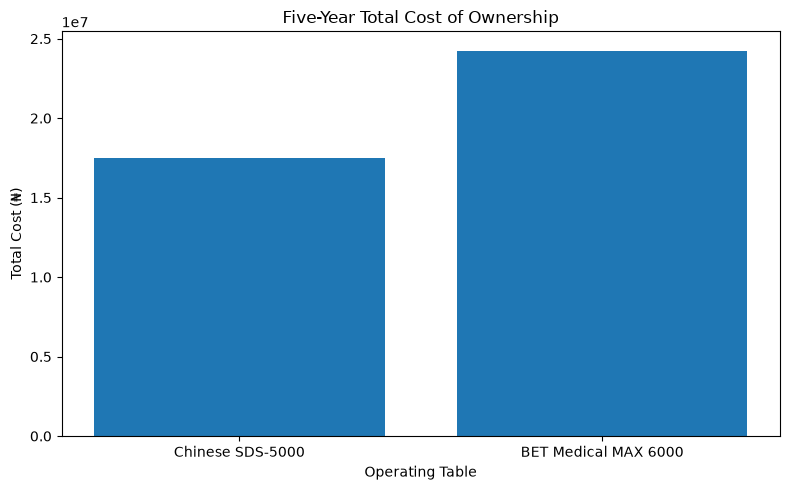

In [12]:
tables = ["Chinese SDS-5000", "BET Medical MAX 6000"]
total_costs = [17500000, 24250000]

plt.figure(figsize=(8, 5))

plt.bar(tables, total_costs)

plt.title("Five-Year Total Cost of Ownership")
plt.ylabel("Total Cost (₦)")
plt.xlabel("Operating Table")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from IPython.display import display

final_data = {
    "Operating Table": [
        "Chinese SDS-5000",
        "BET Medical MAX 600"
    ],
    "Purchase and Replacement": [6000000, 19000000],
    "Maintenance": [1500000, 1250000],
    "Repairs": [2500000, 1000000],
    "Downtime": [7500000, 3000000]
}

final_df = pd.DataFrame(final_data)

cost_columns = [
    "Purchase and Replacement",
    "Maintenance",
    "Repairs",
    "Downtime"
]

final_df["Total Five-Year Cost"] = final_df[cost_columns].sum(axis=1)

final_df["Cost Ranking"] = (
    final_df["Total Five-Year Cost"]
    .rank(method="min")
    .astype(int)
)

final_df = final_df.sort_values("Cost Ranking")

# Format the financial figures in Naira
formatted_df = final_df.copy()

money_columns = cost_columns + ["Total Five-Year Cost"]

for column in money_columns:
    formatted_df[column] = formatted_df[column].apply(
        lambda value: f"₦{value:,.0f}"
    )

display(formatted_df)

# Saving the original numerical results
final_df.to_csv("operating_table_cost_comparison.csv", index=False)

,Operating Table,Purchase and Replacement,Maintenance,Repairs,Downtime,Total Five-Year Cost,Cost Ranking
0,Chinese SDS-5000,"₦6,000,000","₦1,500,000","₦2,500,000","₦7,500,000","₦17,500,000",1
1,BET Medical MAX 600,"₦19,000,000","₦1,250,000","₦1,000,000","₦3,000,000","₦24,250,000",2
